# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


## Predicción inicial antes de cargar los datos

Antes de observar el dataset Iris, esperaba que la distribución de las medidas tuviera una forma parecida a una campana de Gauss.

También pensé que el dataset tendría más características para describir las flores de una manera más completa. Por ejemplo, esperaba el **color de la flor** y sobre el **tiempo que tarda en crecer**. 

Sin embargo, el dataset Iris solamente incluye cuatro medidas numéricas: longitud y ancho del sépalo, y longitud y ancho del pétalo.


In [11]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data
y = iris.target

print("Cada instancia representa una flor de la especie Iris.")
print(f"Número de instancias: {X.shape[0]}")
print(f"Número de características: {X.shape[1]}")
print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

datos_iris = pd.DataFrame(X, columns=iris.feature_names)

datos_iris["species"] = [iris.target_names[etiqueta] for etiqueta in y]

# Mostrar las primeras 5 instancias
display(datos_iris.head(5))

Cada instancia representa una flor de la especie Iris.
Número de instancias: 150
Número de características: 4
Dimensiones de X: (150, 4)
Dimensiones de y: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


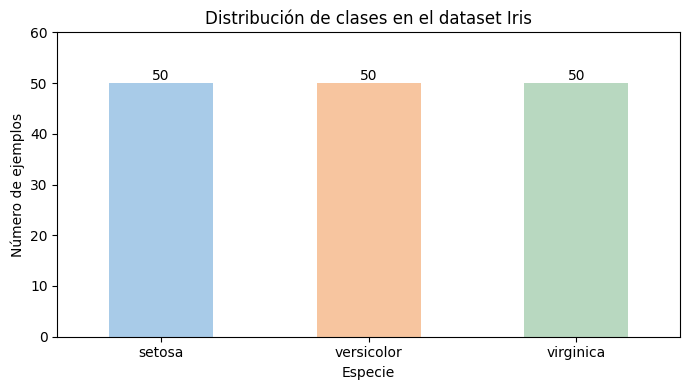

In [12]:
# Gráfico de distribución de las clases
conteo_clases = datos_iris["species"].value_counts().reindex(iris.target_names)

ax = conteo_clases.plot(
    kind="bar",
    color=["#A8CBE8", "#F7C59F", "#B8D8C0"],
    figsize=(7, 4),
    rot=0,
)

ax.set_title("Distribución de clases en el dataset Iris")
ax.set_xlabel("Especie")
ax.set_ylabel("Número de ejemplos")
ax.set_ylim(0, conteo_clases.max() + 10)

# Mostrar la cantidad encima de cada barra
for barra, cantidad in zip(ax.patches, conteo_clases):
    ax.annotate(
        str(cantidad),
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

## Interpretación y respuestas

**1. ¿Qué representa cada instancia?**

Cada instancia representa una flor de Iris. Cada fila contiene cuatro medidas físicas de la flor y su especie: dos medidas del sépalo y dos del pétalo.

**2. ¿Cuál es el número de instancias y características?**

El dataset contiene **150 instancias** y **4 características numéricas** por instancia.

**3. ¿Cuál es el nombre y significado de cada característica?**

- **Longitud del sépalo**: medida del sépalo desde la base hasta la punta.
- **Ancho del sépalo**: medida del sépalo de lado a lado.
- **Longitud del pétalo**: medida del pétalo desde la base hasta la punta.
- **Ancho del pétalo**: medida del pétalo de lado a lado.

Todas las medidas están expresadas en centímetros. Estas características se utilizan para describir cada flor y predecir su especie.

### 4. ¿Cuáles son las clases y cuántos ejemplos hay por clase?

Las clases son **setosa, versicolor y virginica**. Cada clase tiene **50 ejemplos**, por lo que la distribución está equilibrada.

### 5. ¿Cuáles son las dimensiones de la matriz de características y del vector de etiquetas?

La matriz de características `X` tiene dimensiones **(150, 4)**. El vector de etiquetas `y` tiene dimensiones **(150,)**.

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

**1. ¿Qué modelos crees que serán sensibles a las escalas de las características?**

   Espero que los sensibles sean regresion logistica,**SVM y MLP** debido a  que sus escalas pueden ser diferentes

**2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?**

   El **árbol de decisión** , porque divide los datos con reglas sencillas

**3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?**

   Porque cada modelo aprende de una forma diferente. El mejor resultado depende de los datos, los hiperparámetros y la separación entre las clases.

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.


### Preparación común

Usaremos las mismas 150 flores de Iris. Las separamos en 90 para entrenamiento, 30 para validación y 30 para prueba. La opción stratify conserva la proporción de las tres especies.

Todos los modelos usarán estas mismas particiones. Cada modelo tendrá su propio Pipeline con StandardScaler. El escalador aprende las medias y desviaciones solamente con entrenamiento y usa esas medidas en validación y prueba. Así evitamos filtrar información de los conjuntos reservados.

La validación servirá para comparar configuraciones. Después de elegir una configuración, no se modifica durante la evaluación final en prueba.

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)
print(X_train.shape[0], "entrenamiento")
print(X_val.shape[0], "validación")
print(X_test.shape[0], "prueba")

def evaluar_validacion(modelo):
    modelo.fit(X_train, y_train)
    return f1_score(y_val, modelo.predict(X_val), average="macro")

def elegir_modelo(configuraciones):
    resultados = [(evaluar_validacion(modelo), nombre, modelo) for nombre, modelo in configuraciones.items()]
    mejor = max(resultados, key=lambda resultado: resultado[0])
    display(pd.DataFrame([(nombre, f1) for f1, nombre, _ in resultados], columns=["Configuración", "F1 validación"]).round(3))
    print("Configuración elegida:", mejor[1])
    return mejor[2]

90 entrenamiento
30 validación
30 prueba


### Gaussian Naive Bayes

Se comparan configuraciones y se elige una usando solamente la validación.

In [6]:
modelo_nb = elegir_modelo({
    "var_smoothing=1e-09": make_pipeline(StandardScaler(), GaussianNB(var_smoothing=1e-9)),
    "var_smoothing=1e-08": make_pipeline(StandardScaler(), GaussianNB(var_smoothing=1e-8)),
})

,Configuración,F1 validación
0,var_smoothing=1e-09,0.933
1,var_smoothing=1e-08,0.933


Configuración elegida: var_smoothing=1e-09


### Regresión logística multiclase

Se comparan configuraciones y se elige una usando solamente la validación.

In [7]:
modelo_log = elegir_modelo({
    "C=0.1": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000)),
    "C=1.0": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)),
})

,Configuración,F1 validación
0,C=0.1,0.865
1,C=1.0,0.933


Configuración elegida: C=1.0


### SVM lineal

Se comparan configuraciones y se elige una usando solamente la validación.

In [8]:
modelo_svm = elegir_modelo({
    "C=0.1": make_pipeline(StandardScaler(), LinearSVC(C=0.1, random_state=42)),
    "C=1.0": make_pipeline(StandardScaler(), LinearSVC(C=1.0, random_state=42)),
})

,Configuración,F1 validación
0,C=0.1,0.829
1,C=1.0,0.933


Configuración elegida: C=1.0


### Árbol de decisión

Se comparan configuraciones y se elige una usando solamente la validación.

In [9]:
modelo_arbol = elegir_modelo({
    "max_depth=2": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=2, random_state=42)),
    "max_depth=3": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=3, random_state=42)),
})

,Configuración,F1 validación
0,max_depth=2,0.900
1,max_depth=3,0.967


Configuración elegida: max_depth=3


### Random Forest

Se comparan configuraciones y se elige una usando solamente la validación.

In [10]:
modelo_rf = elegir_modelo({
    "n_estimators=100": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42)),
    "n_estimators=150": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=150, random_state=42)),
})

,Configuración,F1 validación
0,n_estimators=100,0.933
1,n_estimators=150,0.933


Configuración elegida: n_estimators=100


### Gradient Boosting

Se comparan configuraciones y se elige una usando solamente la validación.

In [11]:
modelo_gb = elegir_modelo({
    "n_estimators=50": make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=50, random_state=42)),
    "n_estimators=100": make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=100, random_state=42)),
})

,Configuración,F1 validación
0,n_estimators=50,0.933
1,n_estimators=100,0.933


Configuración elegida: n_estimators=50


### MLP de clasificación

Se comparan configuraciones y se elige una usando solamente la validación.

In [12]:
modelo_mlp = elegir_modelo({
    "hidden_layer_sizes=(10,)": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(10,), max_iter=2000, random_state=42)),
    "hidden_layer_sizes=(20,)": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(20,), max_iter=2000, random_state=42)),
})

,Configuración,F1 validación
0,"hidden_layer_sizes=(10,)",0.967
1,"hidden_layer_sizes=(20,)",0.967


Configuración elegida: hidden_layer_sizes=(10,)


### Evaluación final

Las configuraciones ya están congeladas. Entrenamos cada modelo elegido con entrenamiento y evaluamos una sola vez sobre la misma prueba. Esta tabla no se usa para volver a ajustar los modelos.

,Modelo,Accuracy,F1 macro
3,Árbol,1.000,1.000
5,Gradient Boosting,0.967,0.967
6,MLP,0.967,0.967
0,Naive Bayes,0.933,0.933
1,Regresión logística,0.933,0.933
2,SVM lineal,0.900,0.900
4,Random Forest,0.900,0.898


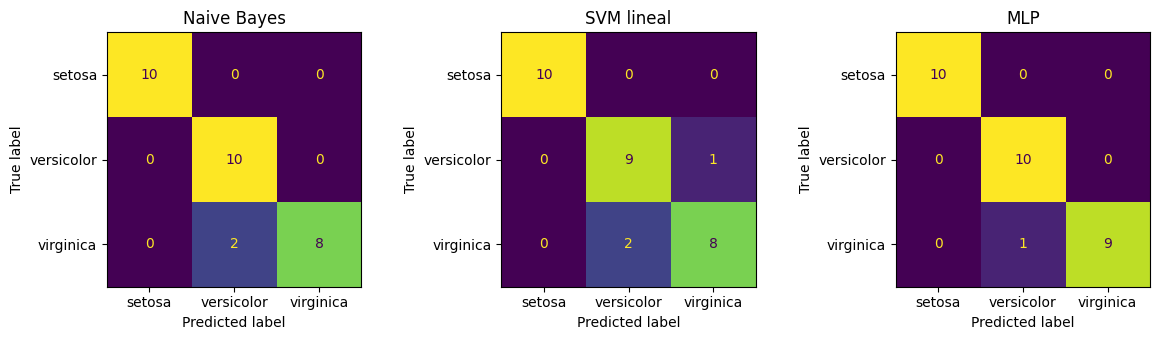

In [13]:
modelos_finales = {
    "Naive Bayes": modelo_nb,
    "Regresión logística": modelo_log,
    "SVM lineal": modelo_svm,
    "Árbol": modelo_arbol,
    "Random Forest": modelo_rf,
    "Gradient Boosting": modelo_gb,
    "MLP": modelo_mlp,
}
resultados = []
for nombre, modelo in modelos_finales.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    resultados.append({"Modelo": nombre, "Accuracy": accuracy_score(y_test, pred), "F1 macro": f1_score(y_test, pred, average="macro")})
resultados_clasificacion = pd.DataFrame(resultados).sort_values("F1 macro", ascending=False)
display(resultados_clasificacion.round(3))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, nombre in zip(axes, ["Naive Bayes", "SVM lineal", "MLP"]):
    ConfusionMatrixDisplay.from_predictions(y_test, modelos_finales[nombre].predict(X_test), display_labels=iris.target_names, ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

## Interpretación

**1. ¿Cuál fue el modelo con el mejor desempeño?**

El **árbol de decisión** fue el mejor, con accuracy = 1.00 y F1 macro = 1.00.

**2. ¿Cuál fue el modelo más sencillo de programar?**

**Naive Bayes**, porque necesita pocos parámetros y poco código.

**3. ¿Accuracy y F1 macro cuentan la misma historia?**

Sí, casi. En este dataset dieron resultados muy parecidos porque las clases están balanceadas.

**4. ¿Cuál es la diferencia entre las métricas macro y micro?**

**Macro** da la misma importancia a cada clase. **Micro** calcula el resultado usando todos los ejemplos juntos.

**5. ¿Qué aporta el MLP frente a un modelo lineal?**

El MLP puede aprender relaciones no lineales. En esta prueba obtuvo **accuracy = 0.967** y **F1 macro = 0.967**, pero no superó al árbol.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

El objetivo numérico es una medida de progresión de la enfermedad un año después del inicio del estudio. Las diez características están estandarizadas y centradas; por eso sus valores no deben interpretarse directamente como unidades clínicas originales.

## Predicción inicial

Un modelo más flexible no siempre tendrá menor error en datos nuevos. Puede ajustarse demasiado al entrenamiento y generalizar peor (**sobreajuste**). Espero que los modelos regularizados y los ensambles logren un equilibrio entre flexibilidad y generalización.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

## Interpretación

1. El mejor modelo es el que tenga menor RMSE y un MAE bajo en prueba.
2. MAE usa el error absoluto y trata todos los errores de forma lineal. RMSE eleva al cuadrado los errores y penaliza más los casos grandes.
3. Un R² negativo significa que el modelo predice peor que usar como predicción constante la media del objetivo.
4. Al aumentar la regularización, los coeficientes disminuyen; en Lasso algunos pueden hacerse cero. Si es excesiva, aparece subajuste.
5. Los errores grandes pueden deberse a observaciones atípicas, ruido, variables no incluidas o relaciones no lineales.
6. Un coeficiente predictivo muestra asociación condicionada al modelo, no demuestra una relación causal.

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import TransformedTargetRegressor
import numpy as np

diabetes = load_diabetes()
Xr, yr = diabetes.data, diabetes.target
Xr_train, Xr_tmp, yr_train, yr_tmp = train_test_split(Xr, yr, test_size=0.30, random_state=42)
Xr_val, Xr_test, yr_val, yr_test = train_test_split(Xr_tmp, yr_tmp, test_size=0.50, random_state=42)

modelos_reg = {
    "Lineal": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.01, max_iter=10000)),
    "kNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    "Árbol": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "MLP": TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32,), alpha=0.001, max_iter=3000, random_state=42)),
        transformer=StandardScaler(),
    ),
}

resultados_reg = []
for nombre, modelo in modelos_reg.items():
    modelo.fit(Xr_train, yr_train)
    pred = modelo.predict(Xr_test)
    resultados_reg.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": mean_squared_error(yr_test, pred) ** 0.5,
        "R²": r2_score(yr_test, pred),
    })

tabla_regresion = pd.DataFrame(resultados_reg).sort_values("RMSE")
display(tabla_regresion.round(2))

for nombre in ["Lineal", "MLP"]:
    pred = modelos_reg[nombre].predict(Xr_test)
    residuos = yr_test - pred
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].scatter(yr_test, pred, alpha=0.7)
    axes[0].plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], "k--")
    axes[0].set(xlabel="Real", ylabel="Predicción", title=f"{nombre}: real vs. predicción")
    axes[1].scatter(pred, residuos, alpha=0.7)
    axes[1].axhline(0, color="k", linestyle="--")
    axes[1].set(xlabel="Predicción", ylabel="Residuo", title=f"{nombre}: residuos")
    plt.tight_layout()
    plt.show()
    indices = np.argsort(np.abs(residuos))[-2:][::-1]
    print(nombre, "errores grandes:", [(int(i), round(float(yr_test[i]), 1), round(float(pred[i]), 1), round(float(abs(residuos[i])), 1)) for i in indices])

penalizaciones = [0.01, 0.1, 1, 10, 100]
regularizacion = []
for alpha in penalizaciones:
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xr_train, yr_train)
    lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000)).fit(Xr_train, yr_train)
    regularizacion.append({
        "alpha": alpha,
        "Ridge validación": mean_squared_error(yr_val, ridge.predict(Xr_val)) ** 0.5,
        "Lasso validación": mean_squared_error(yr_val, lasso.predict(Xr_val)) ** 0.5,
        "Ridge coef. máx.": np.max(np.abs(ridge[-1].coef_)),
        "Lasso ceros": np.sum(lasso[-1].coef_ == 0),
    })
display(pd.DataFrame(regularizacion).round(3))

## Cierre

Los resultados deben interpretarse usando la partición de prueba solo después de congelar las configuraciones. La flexibilidad mejora el ajuste únicamente cuando también mejora la generalización; por eso se comparan simultáneamente las métricas de validación y prueba.